# Solutions: Chapter 21, Time Series Analysis

Worked solutions to the exercises at the end of Chapter 21 of *Python for Data Science* by Vamsi Krishna Kandala. Try each exercise on your own first. Run the code yourself with the notebook [`ch21_solutions.ipynb`](ch21_solutions.ipynb) or the script `ch21_solutions.py`.

Numbers that depend on random data or library versions may differ slightly on your computer; the conclusions should not.


In [ ]:
# Setup: recreates the context these solutions build on (from the chapter).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

bikes = pd.read_csv("data/bike_daily.csv", parse_dates=["date"],
                    index_col="date")
daily = bikes.asfreq("D")
daily["rides"] = daily["rides"].interpolate(method="time")
daily["holiday"] = daily["holiday"].astype("boolean").fillna(False)
rides = daily["rides"]
smooth28 = rides.rolling(28, center=True).mean()
train = daily.loc[:"2025-09-30"]
test = daily.loc["2025-10-01":]
actual = test["rides"]


def errors(forecast):
    e = actual - forecast
    return {"MAE": e.abs().mean(),
            "MAPE %": (e / actual).abs().mean() * 100}


def features(df, weather=True):
    X = pd.DataFrame({"t": (df.index - daily.index[0]).days,
                      "holiday": df["holiday"].astype(int)},
                     index=df.index)
    if weather:
        X["temp"] = df["temp_max_c"]
        X["rain"] = np.log1p(df["precip_mm"])
    days = pd.Categorical(df.index.dayofweek, categories=range(7))
    dow = pd.get_dummies(days, prefix="dow", dtype=int)
    return X.join(dow.set_index(df.index))

The solutions start from the chapter's daily series with the gap filled, its training and test periods, the `errors` function, and a version of `features` with an option to leave out the weather. It makes the weekday a categorical with all seven days, so that `get_dummies` always creates seven columns, even for a stretch of data that doesn't contain every weekday, such as the last, one-day "week" of exercise 7.

## Exercise 21.1

*Find the busiest and the quietest week of 2025 by total rides, and the month with the highest average.*

In [ ]:
weeks = rides.loc["2025"].resample("W").sum()
weeks = weeks.iloc[1:-1]                     # drop the partial weeks
print("busiest:", weeks.idxmax().date(), int(weeks.max()))
print("quietest:", weeks.idxmin().date(), int(weeks.min()))
monthly = rides.loc["2025"].resample("MS").mean()
print("best month:", monthly.idxmax().strftime("%B"),
      round(monthly.max()))

busiest: 2025-07-20 16106
quietest: 2025-02-02 8123
best month: July 2129


`rides.loc["2025"]` selects the year by a partial date string. 2025 begins on a Wednesday and ends on a Wednesday, so the first and last "weeks" are partial and would look quiet for the wrong reason; dropping them is the check this chapter recommends. The busiest week ended on July 20, the quietest on February 2, and July has the highest daily average.

## Exercise 21.2

*Plot the 7-day rolling mean of rides for 2025 against the 7-day rolling mean of the maximum temperature, on two charts with a shared x axis.*

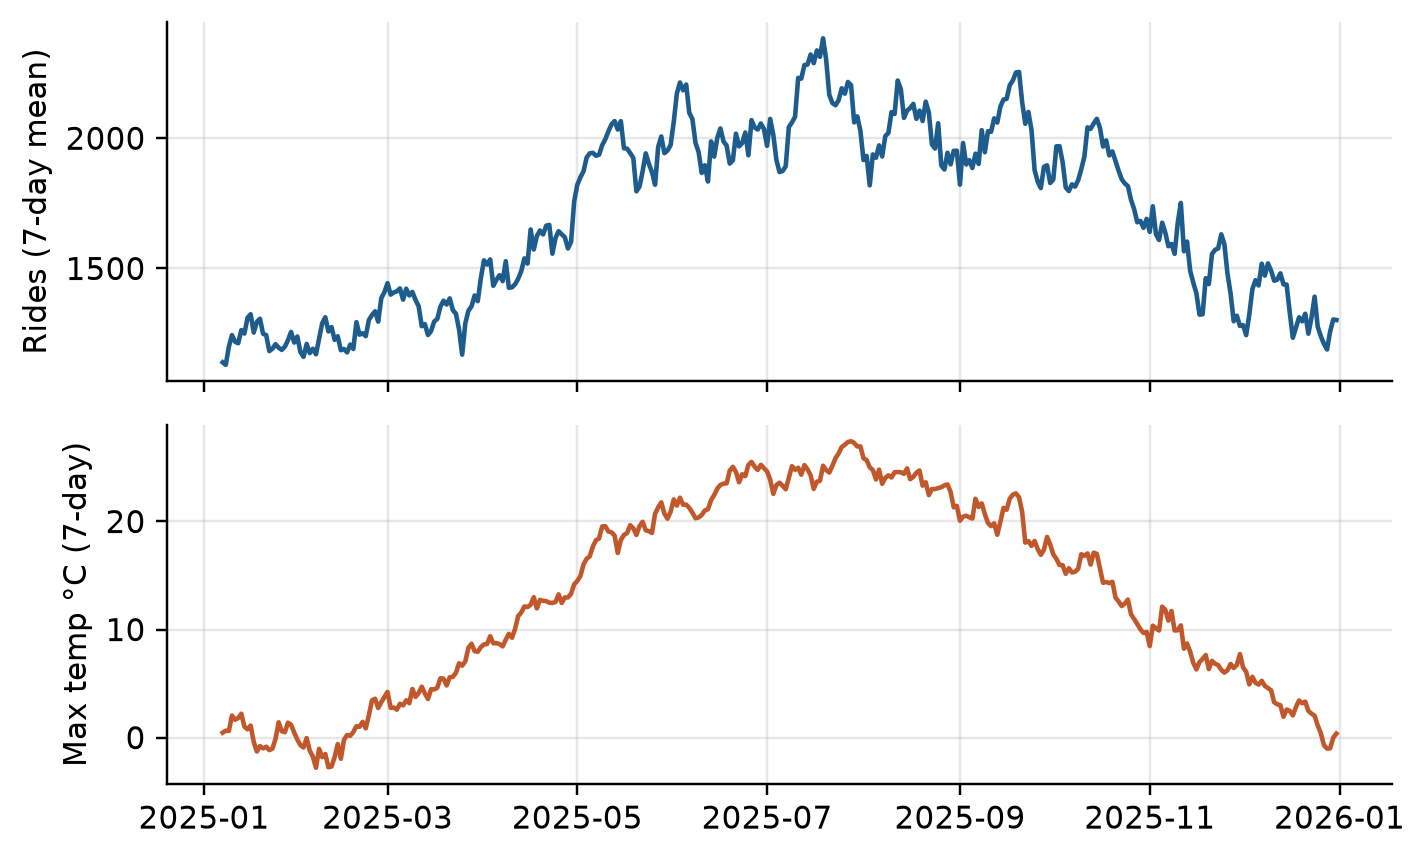

In [ ]:
year = daily.loc["2025"]
fig, axes = plt.subplots(2, 1, figsize=(6.6, 4), sharex=True)
axes[0].plot(year["rides"].rolling(7).mean(), color="#1d5c8c")
axes[0].set_ylabel("Rides (7-day mean)")
axes[1].plot(year["temp_max_c"].rolling(7).mean(), color="#c0582b")
axes[1].set_ylabel("Max temp °C (7-day)")
fig.tight_layout()
plt.show()

*The 7-day mean of daily rides (top) and of the maximum temperature (bottom) in 2025, on a shared time axis.*

Two charts with one x axis, instead of one chart with two y axes (Chapter 15), make the comparison honest: rides rise and fall with the temperature, through spring, summer and fall, and the cold snaps of winter show up in both.

## Exercise 21.3

*Compute the ride factor of each holiday relative to the 28-day centered average, and the average holiday effect.*

In [ ]:
level = rides / smooth28
holidays = level[daily["holiday"]].dropna()
by_day = holidays.groupby(holidays.index.strftime("%m-%d")).mean()
print(by_day.round(2).to_frame("factor").T)
print(f"average holiday: {holidays.mean():.2f}")

date    01-01  05-26  07-04  09-01  11-27  12-25
factor    0.8   0.68    0.8   0.67   0.73   0.85
average holiday: 0.75


Each holiday's rides are divided by the centered 28-day average around it, which removes the season and the trend. Holidays run at about 65 to 85% of a normal day for the time of year, 75% on average; the factor varies a little with the weather of each holiday, which the next exercise looks at for the residuals.

## Exercise 21.4

*Decompose the weekly totals with `seasonal_decompose` and `period=52`. Which weeks have the largest residuals, and what was the weather?*

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

weekly = daily[["rides", "precip_mm"]].resample("W").agg(
    {"rides": "sum", "precip_mm": "sum"}).iloc[1:-1]
parts = seasonal_decompose(weekly["rides"], model="multiplicative",
                           period=52)
resid = parts.resid.dropna()
worst = resid.sort_values().index[:3]
print(pd.DataFrame({"resid": resid[worst].round(2),
                    "rain_mm": weekly.loc[worst, "precip_mm"]}))

            resid  rain_mm
date                      
2022-09-04   0.85     36.6
2023-10-15   0.87     21.4
2024-08-04   0.90     41.0


The residual is what trend and season don't explain; below 1 means fewer rides than expected. The three weeks with the lowest residuals had a lot of rain, far more than a typical week's 10 to 15 millimeters, confirming that weather drives most of the remaining variation.

## Exercise 21.5

*Add a baseline that forecasts each test day as the mean of the same weekday over the last four weeks of training, and compare its errors with the others.*

In [ ]:
last4 = train["rides"].iloc[-28:]
by_dow = last4.groupby(last4.index.dayofweek).mean()
weekday_mean = pd.Series(by_dow.loc[actual.index.dayofweek].values,
                         index=actual.index)
print({k: round(float(v), 1) for k, v in errors(weekday_mean).items()})

{'MAE': 474.6, 'MAPE %': 36.9}


The baseline keeps the weekly rhythm but, like the other flat forecasts, not the fall decline: its average error is about 37%, worse than repeating last week (25%) and much worse than last year scaled by growth (19%). The seasonal pattern of the year matters more than that of the week here.

## Exercise 21.6

*Refit the regression without the weather columns. How much worse is it, and how does it compare with the seasonal baseline?*

In [ ]:
fit_on = train.dropna(subset=["temp_max_c"])
for weather in [True, False]:
    model = LinearRegression().fit(features(fit_on, weather),
                                   np.log(fit_on["rides"]))
    pred = np.exp(model.predict(features(test, weather)))
    pred = pd.Series(pred, actual.index)
    print(f"weather={weather}:",
          {k: round(float(v), 1) for k, v in errors(pred).items()})

weather=True: {'MAE': 99.6, 'MAPE %': 6.6}
weather=False: {'MAE': 325.7, 'MAPE %': 25.2}


Without the weather, the regression knows only the trend, the weekday and holidays. It has no idea of the season, so its forecasts don't follow the fall decline, and its average error, 25%, is worse than the seasonal baseline's 19%. With weather, the temperature carries the season too, which is why that model did so well; a model without weather would need a seasonal feature, such as the month, to compete.

## Exercise 21.7

*Use the regression to forecast each week of the test period from the data available at the start of that week, refitting each week, and compare the weekly errors with the single fit.*

In [ ]:
fit_once = LinearRegression().fit(features(fit_on),
                                  np.log(fit_on["rides"]))
rows = []
for start in pd.date_range("2025-10-01", "2025-12-31", freq="7D"):
    week = daily.loc[start:start + pd.Timedelta(days=6)]
    past = daily.loc[:start - pd.Timedelta(days=1)].dropna(
        subset=["temp_max_c"])
    model = LinearRegression().fit(features(past), np.log(past["rides"]))
    for name, m in [("refit", model), ("once", fit_once)]:
        pred = np.exp(m.predict(features(week)))
        rows.append({"week": start.date(), "model": name,
                     "MAE": np.abs(week["rides"] - pred).mean()})
table = pd.DataFrame(rows).pivot(index="week", columns="model",
                                 values="MAE")
print(table.round(0).head(4))
print(table.mean().round(1).to_dict())

model        once  refit
week                    
2025-10-01  121.0  121.0
2025-10-08   84.0   84.0
2025-10-15  149.0  148.0
2025-10-22  106.0  106.0
{'once': 100.5, 'refit': 100.4}


Each refit uses all data up to the day before the week, as a forecaster working weekly would. The refitted model is practically as good as the single fit, an average error of 100 rides either way: the relationships between weather, weekday and rides are stable, so a model fitted in September still works in December. This kind of **rolling-origin** evaluation is how forecasting systems are tested before they go live.